# EDA: поездки Uber в Нью-Йорке, апрель–сентябрь 2014

Смотрю на данные перед тем как строить модель. Главные вопросы: есть ли тренд, насколько сильная суточная/недельная сезонность, как спрос распределён по городу.

In [1]:
import sys; sys.path.append('..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, h3
from src.prepare import load_raw, filter_bbox
plt.rcParams['figure.figsize'] = (11, 4)
df = filter_bbox(load_raw())
df.shape

вне рамки NYC: 21227 поездок (0.468%)


(4513100, 4)

In [2]:
df.head()

,dt,lat,lon,base
0,2014-04-01 00:11:00,40.7690,-73.9549,B02512
1,2014-04-01 00:17:00,40.7267,-74.0345,B02512
2,2014-04-01 00:21:00,40.7316,-73.9873,B02512
3,2014-04-01 00:28:00,40.7588,-73.9776,B02512
4,2014-04-01 00:33:00,40.7594,-73.9722,B02512


## Тренд по дням

Спрос почти удвоился за полгода — это рост самого Uber, а не сезонность. Для модели это проблема: деревья не экстраполируют, поэтому в признаки нужен «текущий уровень» (скользящее среднее за неделю).

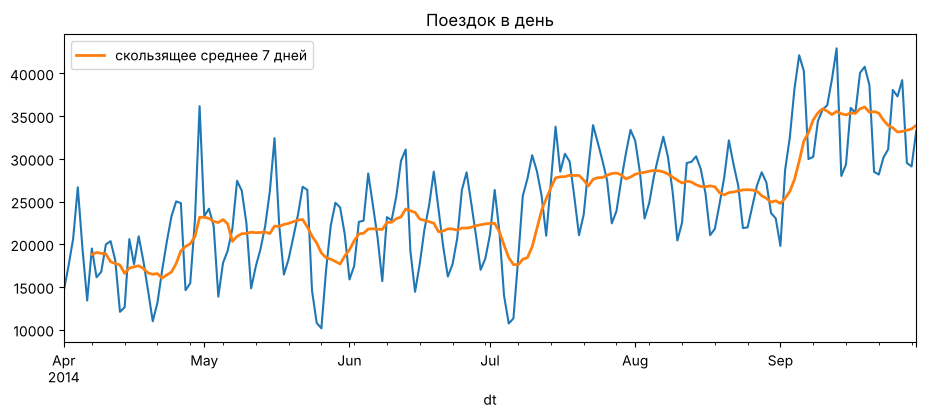

апрель, среднее в день: 18762 | сентябрь: 34101


In [3]:
daily = df.set_index('dt').resample('D').size()
ax = daily.plot(title='Поездок в день')
daily.rolling(7).mean().plot(ax=ax, lw=2, label='скользящее среднее 7 дней')
ax.legend(); plt.show()
print('апрель, среднее в день:', int(daily['2014-04'].mean()), '| сентябрь:', int(daily['2014-09'].mean()))

## Недельная и суточная сезонность

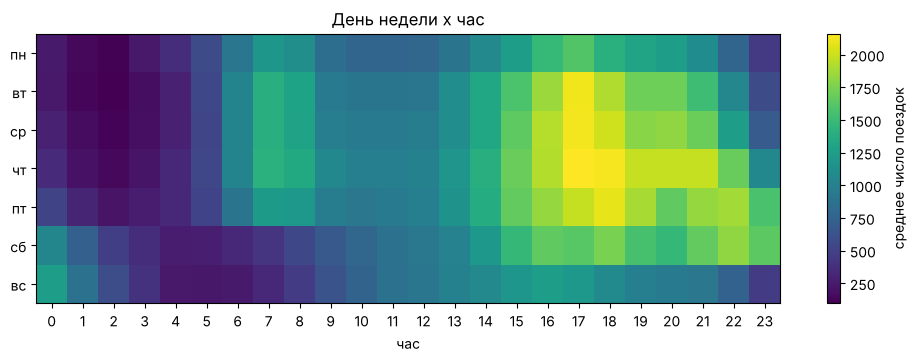

In [4]:
tmp = df.assign(dow=df.dt.dt.dayofweek, hour=df.dt.dt.hour)
pivot = tmp.groupby(['dow', 'hour']).size().unstack() / tmp.dt.dt.normalize().nunique() * 7
fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(pivot, aspect='auto', cmap='viridis')
ax.set_yticks(range(7)); ax.set_yticklabels(['пн','вт','ср','чт','пт','сб','вс'])
ax.set_xticks(range(24)); ax.set_xlabel('час')
plt.colorbar(im, label='среднее число поездок'); ax.set_title('День недели x час'); plt.show()

Будни: два пика (утро ~7–8 и вечер ~17–19), выходные: утреннего пика нет, зато ночью с пт на сб и с сб на вс спрос высокий. Отсюда признак `is_party_night`.

## Пространственное распределение

Разбиваю город на гексагоны H3 (res 7, ~5 км²).

In [5]:
df['cell'] = [h3.latlng_to_cell(a, b, 7) for a, b in zip(df.lat.values, df.lon.values)]
counts = df.cell.value_counts()
share = counts.cumsum() / counts.sum()
print('всего ячеек:', len(counts))
for q in [0.5, 0.8, 0.95, 0.99]:
    print(f'{q:.0%} поездок дают {(share <= q).sum() + 1} ячеек')

всего ячеек: 534
50% поездок дают 4 ячеек
80% поездок дают 14 ячеек
95% поездок дают 38 ячеек
99% поездок дают 106 ячеек


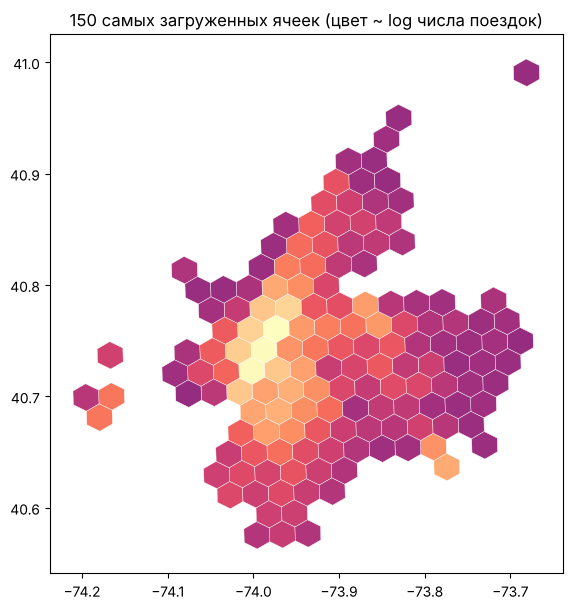

In [6]:
fig, ax = plt.subplots(figsize=(7, 7))
top = counts.head(150)
vmax = np.log10(top.max())
for cell, n in top.items():
    poly = np.array(h3.cell_to_boundary(cell))
    ax.fill(poly[:, 1], poly[:, 0], color=plt.cm.magma(np.log10(n) / vmax), edgecolor='white', lw=0.3)
ax.set_title('150 самых загруженных ячеек (цвет ~ log числа поездок)')
ax.set_aspect(1.3); plt.show()

Спрос очень концентрирован: Манхэттен + аэропорты (JFK, LaGuardia видны отдельными пятнами). около 37 ячеек дают 95% поездок — их и прогнозирую, остальное — длинный хвост почти пустых гексагонов, где почасовой прогноз бессмысленен.

## Нули и выбросы

доля нулевых часов: 0.077


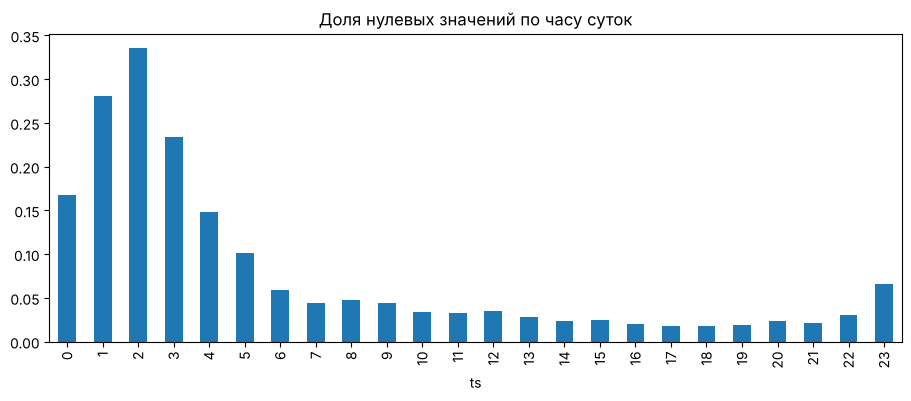

In [7]:
from src.config import PROCESSED_DIR
d = pd.read_parquet(PROCESSED_DIR / 'demand.parquet')
print('доля нулевых часов:', round((d.trips == 0).mean(), 3))
d.groupby(d.ts.dt.hour).trips.apply(lambda s: (s == 0).mean()).plot.bar(title='Доля нулевых значений по часу суток'); plt.show()

Нули почти все ночью на периферийных ячейках. Из-за них не использую MAPE — беру WAPE (сумма абсолютных ошибок / сумма факта).

In [8]:
# праздники: Memorial Day, 4 июля, Labor Day
for day in ['2014-05-26', '2014-07-04', '2014-09-01']:
    d0 = pd.Timestamp(day)
    print(day, int(daily[d0]), 'vs тот же день неделей раньше', int(daily[d0 - pd.Timedelta(days=7)]))

2014-05-26 10157 vs тот же день неделей раньше 18256
2014-07-04 13971 vs тот же день неделей раньше 24798
2014-09-01 19802 vs тот же день неделей раньше 21978
